In [2]:
%pip install contractions

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
pd.options.display.max_columns = 100

**Install NLTK, SpaCy and wordcloud**

# Text cleaning and normalisation

### Contractions

NLP models are sensitive to noise. A machine sees "I'm" and "I am" as different entities. By standardising the text (expanding contractions, removing digits, stripping URLs), we reduce the vocabulary size and prevent the model from learning irrelevant noise.

In [4]:
import contractions

In [5]:
text = "Great weather 5 today, I'm feeling very positiv3. https://www.wikipedia.org/"

# "Great weather today, I'm feeling very positive."

In [6]:
expanded_text = contractions.fix(text) 
expanded_text

'Great weather 5 today, I am feeling very positiv3. https://www.wikipedia.org/'

### Removing numbers and links with regex

In [7]:
import re

text_without_digits = re.sub(r'\b\d+\b', '', expanded_text)

In [8]:
text_without_digits

'Great weather  today, I am feeling very positiv3. https://www.wikipedia.org/'

- \b - Matches the position between a word character (a letter, digit, or underscore) and a non-word character (a space, punctuation, or the start/end of the string). Its primary use is to ensure that a pattern matches a whole word and is not just part of a larger word.

- \d - Matches any digit from 0 to 9.

- "+"  - Matches the preceding element (\d) one or more times. This means it will match 1, 12, 123, and so on.

**5** - It is a digit (\d+) surrounded by a space (\b) and a space (\b).

**positiv3** - the first \b boundary condition is non met as it starts with letters.

We will strip URLs by matching the 'http' or 'https' protocol, optional '//', and subsequent non-whitespace characters (\S+).

In [9]:
text_without_links = re.sub(r'https?:\s*//?\S+|www\.\S+', '', text_without_digits)
text_without_links 

'Great weather  today, I am feeling very positiv3. '

### Lowercase

In [10]:
expanded_text = text_without_links.lower()
expanded_text

'great weather  today, i am feeling very positiv3. '

## NLTK and String package

### Tokenize

NLTK: Natural Language Toolkit

https://www.nltk.org/

"NLTK is a leading platform for building Python programs to work with human language data. It provides easy-to-use interfaces to over 50 corpora and lexical resources such as WordNet, along with a suite of text processing libraries for classification, tokenization, stemming, tagging, parsing, and semantic reasoning, wrappers for industrial-strength NLP libraries, and an active discussion forum."

NLTK is a foundational, research-oriented library. It requires you to build the pipeline manually.   
- **Tokenization** - Chopping text into individual words.
- **Stop Words** - Removing high-frequency, low-value words (e.g., 'the', 'is', 'at') to reduce dimensionality.
- **POS Tagging & Lemmatization** - Lemmatization reduces words to their dictionary root (e.g., 'feeling' -> 'feel'). However, NLTK's lemmatizer needs to know the context of the word to do this accurately. Therefore, we must perform Part-of-Speech (POS) tagging first. 

In [11]:
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\keiron.jones.TETRAD\AppData\Roaming\nltk_data
[nltk_data]     ...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\keiron.jones.TETRAD\AppData\Roaming\nltk_data
[nltk_data]     ...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\keiron.jones.TETRAD\AppData\Roaming\nltk_data
[nltk_data]     ...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [12]:
tokens = word_tokenize(expanded_text)
tokens

['great',
 'weather',
 'today',
 ',',
 'i',
 'am',
 'feeling',
 'very',
 'positiv3',
 '.']

### Remove the Stop Words and Punctuation

In [13]:
from nltk.corpus import stopwords
import string

In [14]:
stop_words = stopwords.words('english')

In [15]:
stop_words[:20]

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been']

In [16]:
punctuation = string.punctuation
punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [17]:
punct_list = list(punctuation)
punct_list.append('...')
print(punct_list)

['!', '"', '#', '$', '%', '&', "'", '(', ')', '*', '+', ',', '-', '.', '/', ':', ';', '<', '=', '>', '?', '@', '[', '\\', ']', '^', '_', '`', '{', '|', '}', '~', '...']


https://www.geeksforgeeks.org/python/string-punctuation-in-python/

In [18]:
filtered_tokens = [
        word for word in tokens 
        if word not in stop_words and 
           word not in punctuation and 
           word.strip() != ''
    ]
filtered_tokens

['great', 'weather', 'today', 'feeling', 'positiv3']

In [19]:
filtered_tokens

['great', 'weather', 'today', 'feeling', 'positiv3']

### POS(Part-of-Speech) Tagging

https://www.nltk.org/api/nltk.tag.pos_tag.html

"The process of classifying words into their parts of speech and labeling them accordingly is known as part-of-speech tagging, POS-tagging, or simply tagging. Parts of speech are also known as word classes or lexical categories. The collection of tags used for a particular task is known as a tagset."
https://www.nltk.org/book/ch05.html

In [20]:
from nltk.tag import pos_tag
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\keiron.jones.TETRAD\AppData\Roaming\nltk_data
[nltk_data]     ...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\keiron.jones.TETRAD\AppData\Roaming\nltk_data
[nltk_data]     ...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger_eng.zip.


True

In [21]:
tokens_pos = pos_tag(filtered_tokens)
tokens_pos

[('great', 'JJ'),
 ('weather', 'NN'),
 ('today', 'NN'),
 ('feeling', 'VBG'),
 ('positiv3', 'NN')]

### Lemmatizer

**lemmatizer.lemmatize('improving', pos='v')**

Expected Output: **'improve'**

https://www.nltk.org/api/nltk.stem.WordNetLemmatizer.html

WordNetLemmatizer only understands simple tags like 'v' (verb), 'n' (noun), 'a' (adjective), or 'r' (adverb)

We need a conversion function to map the detailed POS tags to the simple tags required by the lemmatizer.

In [22]:
from nltk.corpus import wordnet
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\keiron.jones.TETRAD\AppData\Roaming\nltk_data
[nltk_data]     ...


True

NLTK's pos_tag gives detailed Treebank tags, such as 'VBG' for a gerund verb. But the WordNetLemmatizer only works with simple tags like 'v', 'n', 'a', and 'r'. To use the lemmatizer, we need to write a custom function that maps the detailed tags to the simpler ones. This is one of the trade-offs with NLTK: you get more control, but you also have to write extra code.

In [23]:
def get_wordnet_pos(treebank_tag):
    """Map NLTK POS tag to WordNet POS tag"""
    if treebank_tag.startswith('J'):
        return wordnet.ADJ  # Adjective ('a')
    elif treebank_tag.startswith('V'):
        return wordnet.VERB  # Verb ('v')
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN  # Noun ('n')
    elif treebank_tag.startswith('R'):
        return wordnet.ADV  # Adverb ('r')
    else:
        # Default to Noun if the tag is unknown or ambiguous
        return wordnet.NOUN 

In [24]:
from nltk.stem import WordNetLemmatizer

In [25]:
lemmatizer = WordNetLemmatizer()

In [26]:
lem_tokens = []
for word, tag in tokens_pos:
    wntag = get_wordnet_pos(tag) 
    
    lemma = lemmatizer.lemmatize(word, pos=wntag)
    lem_tokens.append(lemma)

In [27]:
tokens_pos

[('great', 'JJ'),
 ('weather', 'NN'),
 ('today', 'NN'),
 ('feeling', 'VBG'),
 ('positiv3', 'NN')]

In [28]:
lem_tokens

['great', 'weather', 'today', 'feel', 'positiv3']

In [29]:
filtered_tokens

['great', 'weather', 'today', 'feeling', 'positiv3']

### Text cleaning function

In [30]:
def nltk_text_cleaning(text):
    expanded_text = contractions.fix(text) 
    text_without_digits = re.sub(r'\b\d+\b', '', expanded_text)
    text_without_links = re.sub(r'https?:\s*//?\S+|www\.\S+', '', text_without_digits)
    expanded_text = text_without_links.lower()
    tokens = word_tokenize(expanded_text)
    filtered_tokens = [
        word for word in tokens 
        if word not in stop_words and 
           word not in punctuation and 
           word.strip() != ''
    ]
    
    tokens_pos = pos_tag(filtered_tokens)
    lemmatizer = WordNetLemmatizer()
    
    lem_tokens = []
    for word, tag in tokens_pos:
        wntag = get_wordnet_pos(tag) 
        
        lemma = lemmatizer.lemmatize(word, pos=wntag)
        lem_tokens.append(lemma)
    return " ".join(lem_tokens) 

In [31]:
text_1 = "It's a beautiful day, isn't it? The birds are singing and the flowers are blooming."

In [32]:
nltk_lemma = nltk_text_cleaning(text_1)
nltk_lemma

'beautiful day bird sing flower bloom'

## SpaCy

In [33]:
import spacy

SpaCy is different from NLTK because it is a powerful, object-oriented library designed for real-world use. When you run text through nlp(), it automatically handles tasks like tokenization, tagging, parsing, and lemmatization using fast C/Cython code.

You can see that the doc object includes the lemma (.lemma_), punctuation flags (.is_punct), and stop word flags (.is_stop) automatically. SpaCy saves developers time by handling these details for you.

"spaCy is a free, open-source library for advanced Natural Language Processing (NLP) in Python. It’s **designed specifically for production use and helps you build applications that process and “understand” large volumes of text**. It can be used to build information extraction or natural language understanding systems."

https://spacy.io/usage/facts-figures

We will download the small English model ('en_core_web_sm')

In [34]:
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     - -------------------------------------- 0.5/12.8 MB 1.8 MB/s eta 0:00:07
     --- ------------------------------------ 1.0/12.8 MB 2.2 MB/s eta 0:00:06
     ---- ----------------------------------- 1.6/12.8 MB 2.2 MB/s eta 0:00:06
     ------ --------------------------------- 2.1/12.8 MB 2.3 MB/s eta 0:00:05
     --------- ------------------------------ 2.9/12.8 MB 2.4 MB/s eta 0:00:05
     --------- ------------------------------ 3.1/12.8 MB 2.5 MB/s eta 0:00:04
     ------------ --------------------------- 3.9/12.8 MB 2.5 MB/s eta 0:00:04
     --------------- ------------------------ 5.0/12.8 MB 2.7 MB/s eta 0:00:03
     ------------------ --------------------- 5.8/12.8 MB 2.9 MB/s eta 0:00:03
     -------------------- ------------------- 6.6/12.8 MB 3.0 MB/s eta 0:


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
nlp = spacy.load("en_core_web_sm")

# "en_core_web_md" and "en_core_web_lg" models for higher lemmatization accuracy.

In [36]:
text_without_digits

'Great weather  today, I am feeling very positiv3. https://www.wikipedia.org/'

In [37]:
doc = nlp(text_without_digits)
doc

Great weather  today, I am feeling very positiv3. https://www.wikipedia.org/

The 'doc' object contains all tokens with features.

**.lemma_** is the lemmatized base form of the word

**.is_punct** and **.is_space** automatically handle punctuation and spacing

In [38]:
for token in doc:
    print(f"Token: {token.text}\t| Lemma: {token.lemma_}\t| POS: {token.pos_}")

Token: Great	| Lemma: great	| POS: ADJ
Token: weather	| Lemma: weather	| POS: NOUN
Token:  	| Lemma:  	| POS: SPACE
Token: today	| Lemma: today	| POS: NOUN
Token: ,	| Lemma: ,	| POS: PUNCT
Token: I	| Lemma: I	| POS: PRON
Token: am	| Lemma: be	| POS: AUX
Token: feeling	| Lemma: feel	| POS: VERB
Token: very	| Lemma: very	| POS: ADV
Token: positiv3	| Lemma: positiv3	| POS: NOUN
Token: .	| Lemma: .	| POS: PUNCT
Token: https://www.wikipedia.org/	| Lemma: https://www.wikipedia.org/	| POS: NOUN


In [39]:
lemmas = [
        token.lemma_ 
        for token in doc 
        if not token.is_stop and 
           not token.is_punct and 
           not token.is_space
]

In [40]:
lemmas

['great', 'weather', 'today', 'feel', 'positiv3', 'https://www.wikipedia.org/']

In [41]:
def spacy_text_cleaning(text):
    text_without_digits = re.sub(r'\b\d+\b', '', text)
    text_without_links = re.sub(r'https?:\s*//?\S+|www\.\S+', '', text_without_digits)
    doc = nlp(text_without_digits)
    
    lemmas = [
            token.lemma_ 
            for token in doc 
            if not token.is_stop and 
               not token.is_punct and 
               not token.is_space
    ]
    return lemmas

In [42]:
text_1

"It's a beautiful day, isn't it? The birds are singing and the flowers are blooming."

In [43]:
import time
start_time = time.time()

print(spacy_text_cleaning(text_1))

print("--- %s seconds ---" % (time.time() - start_time))

['beautiful', 'day', 'bird', 'sing', 'flower', 'bloom']
--- 0.027597665786743164 seconds ---


In [44]:
start_time = time.time()

print(nltk_text_cleaning(text_1))

print("--- %s seconds ---" % (time.time() - start_time))

beautiful day bird sing flower bloom
--- 0.004197597503662109 seconds ---


When you run time.time(), NLTK is faster than SpaCy on a single string, taking about 0.0008 seconds compared to SpaCy’s 0.0058 seconds. This happens because SpaCy loads large statistical models and sets up its whole pipeline, which adds extra time for small, isolated strings. NLTK, by contrast, uses simple Python dictionary lookups. But if you process millions of rows in a real production setting, SpaCy’s performance advantage becomes clear, and the situation reverses.

# Twitter Airline dataset

https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment/data

In [45]:
tweets = pd.read_csv('Tweets.csv')

In [46]:
tweets.head(10)

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)
5,570300767074181121,negative,1.0000,Can't Tell,0.6842,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica seriously would pay $30 a fligh...,NaN,2015-02-24 11:14:33 -0800,NaN,Pacific Time (US & Canada)
6,570300616901320704,positive,0.6745,NaN,0.0000,Virgin America,NaN,cjmcginnis,NaN,0,"@VirginAmerica yes, nearly every time I fly VX...",NaN,2015-02-24 11:13:57 -0800,San Francisco CA,Pacific Time (US & Canada)
7,570300248553349120,neutral,0.6340,NaN,NaN,Virgin America,NaN,pilot,NaN,0,@VirginAmerica Really missed a prime opportuni...,NaN,2015-02-24 11:12:29 -0800,Los Angeles,Pacific Time (US & Canada)
8,570299953286942721,positive,0.6559,NaN,NaN,Virgin America,NaN,dhepburn,NaN,0,"@virginamerica Well, I didn't…but NOW I DO! :-D",NaN,2015-02-24 11:11:19 -0800,San Diego,Pacific Time (US & Canada)
9,570295459631263746,positive,1.0000,NaN,NaN,Virgin America,NaN,YupitsTate,NaN,0,"@VirginAmerica it was amazing, and arrived an ...",NaN,2015-02-24 10:53:27 -0800,Los Angeles,Eastern Time (US & Canada)


In [47]:
tweets['airline_sentiment'].value_counts()

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

In [48]:
print(tweets['text'][2])

@VirginAmerica I didn't today... Must mean I need to take another trip!


## Pandas methods for text cleaning

Pandas has built in a number of vectorised methods that perform the same operations for strings in series as Python string methods. 
**Series.str.method_name()**

A few methods are here:

- Series.str.split()
- Series.str.strip()
- Series.str.lower()
- Series.str.upper()
- Series.str.get()
- Series.str.replace()
- Series.str.cat()
- Series.str.extract()
- Series.str.len()

Documentation, methods explanation, examples: https://pandas.pydata.org/pandas-docs/stable/user_guide/text.html

### Split

In [49]:
tweets[['company_tag', 'cleaned_text']] = tweets['text'].str.split(' ', n=1, expand = True)

In [50]:
tweets.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone,company_tag,cleaned_text
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada),@VirginAmerica,What @dhepburn said.
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica,plus you've added commercials to the experienc...
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada),@VirginAmerica,I didn't today... Must mean I need to take ano...
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica,"it's really aggressive to blast obnoxious ""ent..."
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica,and it's a really big bad thing about it


In [51]:
start_time = time.time()

tweets['cleaned_text'].apply(nltk_text_cleaning)

print(f"--- {time.time() - start_time} seconds ---")

--- 21.044771194458008 seconds ---


In [52]:
start_time = time.time()

tweets['cleaned_text'].apply(spacy_text_cleaning)

print(f"--- {time.time() - start_time} seconds ---")

--- 122.11955118179321 seconds ---


SpaCy loads the entire pipeline (tokenizer, tagger, parser, etc.) and allocates/releases memory resources. Calling once for every row in our DataFrame via .apply(), results in massive cumulative overhead.

To benefit from the SpaCy's speed advantage(which is built with Cython for production use), we will process the text in batches using the dedicated streaming function, and only run the necessary components.

Since we only need tokenization and the Tagger (for lemmatization), we can disable the heaviest parts of the pipeline.

In [53]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
# ner - Named Entity Recognition

The **nlp.pipe()** function is designed to stream text through the pipeline with minimal overhead, reusing memory and even leveraging multiple CPU cores.

In [54]:
def preprocess_text(text):
    text_without_digits = re.sub(r'\b\d+\b', '', text)
    return re.sub(r'https?:\s*//?\S+|www\.\S+', '', text_without_digits)

# fill missing values with an empty string to prevent NoneType errors during processing
tweets['cleaned_text'] = tweets['cleaned_text'].fillna('')

cleaned_raw_texts = [preprocess_text(t) for t in tweets['cleaned_text']]


In [55]:
cleaned_raw_texts

['What @dhepburn said.',
 "plus you've added commercials to the experience... tacky.",
 "I didn't today... Must mean I need to take another trip!",
 'it\'s really aggressive to blast obnoxious "entertainment" in your guests\' faces &amp; they have little recourse',
 "and it's a really big bad thing about it",
 "seriously would pay $ a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA",
 'yes, nearly every time I fly VX this “ear worm” won’t go away :)',
 'Really missed a prime opportunity for Men Without Hats parody, there. ',
 "Well, I didn't…but NOW I DO! :-D",
 "it was amazing, and arrived an hour early. You're too good to me.",
 'did you know that suicide is the second leading cause of death among teens -',
 'I &lt; pretty graphics. so much better than minimal iconography. :D',
 "This is such a great deal! Already thinking about my 2nd trip to @Australia &amp; I haven't even gone on my 1st trip yet! ;p",
 "@virginmedia I'm flying your #

In [56]:
start_time = time.time()

processed_tweets = []

    # Process documents in batches of 1000 to minimise pipeline overhead.
    # n_process=1 - forces single-process execution, which sometimes eliminates unexpected multi-processing overhead.
for doc in nlp.pipe(cleaned_raw_texts, batch_size=1000, n_process=1): 
    tokens = [
        token.lemma_ 
        for token in doc 
        if not token.is_stop and not token.is_punct and not token.is_space
    ]
    processed_tweets.append(" ".join(tokens))

print(f"--- {time.time() - start_time} seconds ---")

--- 22.334702491760254 seconds ---


In [57]:
tweets['cleaned_text_spacy'] = processed_tweets

In [58]:
tweets['cleaned_text_nltk'] = tweets['cleaned_text'].apply(nltk_text_cleaning)

**NLTK** - Performs fast, simple, dedicated lookups on each word. The code is pure Python and less resource-intensive per step.

**SpaCy** - Executes an advanced, sequential statistical model pipeline (Tokenizer → Tagger → Lemmatizer) using optimized Cython code. Even with components disabled, it is running a more complex AI prediction, which has a higher fixed cost than a pure lookup.

In [59]:
tweets['cleaned_text_nltk']

0                                             dhepburn say
1               plus added commercial experience ... tacky
2               today ... must mean need take another trip
3        really aggressive blast obnoxious `` entertain...
4                                     really big bad thing
                               ...                        
14635                   thank get different flight chicago
14636    leave minute late flight warning communication...
14637           please bring american airline blackberry10
14638    money change flight answer phone suggestion ma...
14639    people need know many seat next flight plz put...
Name: cleaned_text_nltk, Length: 14640, dtype: str

#### Task 1:

Perform data cleaning and normalisation on the food reviews dataset. Use any library you prefer.

# EDA

## Word Cloud visualisation

Word Clouds can help with quick stakeholder presentations, but they offer little analytical depth. They hide how often terms appear and make it hard to compare them with numbers. We include one here to give a general sense of the data, but as Data Specialists, we should quickly move on to looking at actual frequency distributions.

In [60]:
all_words = ' '.join(tweets['cleaned_text_nltk'])

In [61]:
all_words

"dhepburn say plus added commercial experience ... tacky today ... must mean need take another trip really aggressive blast obnoxious `` entertainment '' guest face amp little recourse really big bad thing seriously would pay flight seat play really bad thing fly va yes nearly every time fly vx “ ear worm ” go away really missed prime opportunity men without hat parody well not…but -d amaze arrive hour early good know suicide second lead death among teen lt pretty graphic much good minimal iconography great deal already think 2nd trip australia amp even go 1st trip yet p virginmedia fly fabulous seductive sky take stress away travel thanks sfo-pdx schedule still mia excite first cross country flight lax mco heard nothing great thing virgin america 29daystogo flew nyc sfo last week could fully sit seat due two large gentleman either side help ❤️ fly virginamerica ☺️👍 know would amazingly awesome bos-fll please want fly first fare may three time carrier seat available select love graphic

In [62]:
from wordcloud import WordCloud

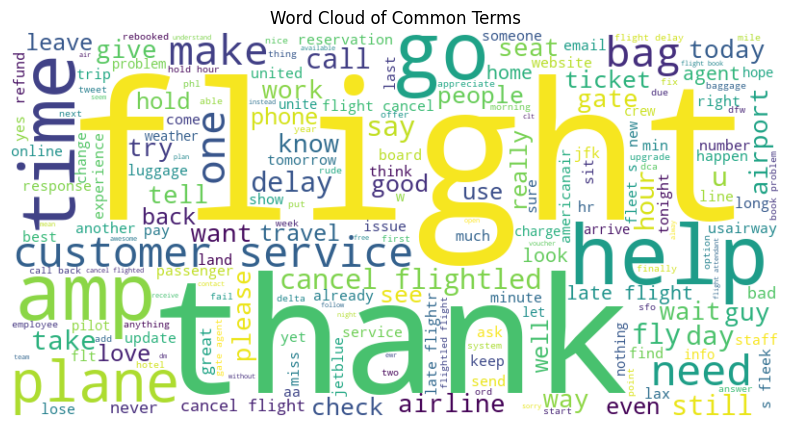

In [63]:
wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color='white'
).generate(all_words)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Word Cloud of Common Terms")
plt.show()

## Frequency Bar Plot

We will tokenize and count word frequencies.

In [64]:
all_tokens = all_words.split()
word_freq = pd.Series(all_tokens).value_counts().head(10)

Plotting the top 10 most frequent words helps us understand the main features of our dataset. In most natural language data, word frequencies follow Zipf's Law. Finding these top words helps us notice "domain-specific stop words," which are words that show up a lot in this dataset (like "flight" or "plane") but are not included in NLTK's general stop word list.

In [65]:
word_freq

flight      4682
get         2101
thanks      1165
hour        1138
service      993
cancel       970
time         952
help         945
customer     934
delay        878
Name: count, dtype: int64

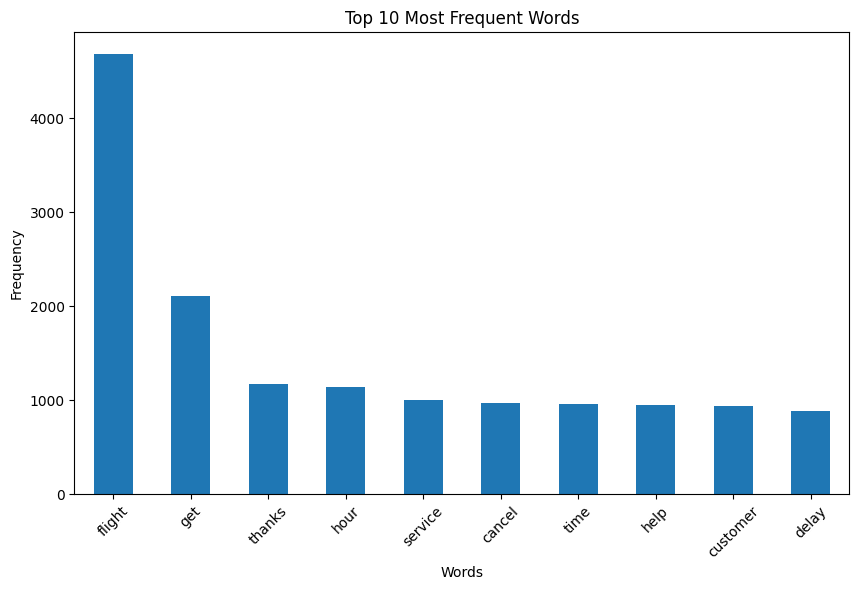

In [66]:
plt.figure(figsize=(10, 6))
word_freq.plot(kind='bar')
plt.title("Top 10 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

#### Optional Task: Segmented Visualisation
Create separate word clouds or frequency plots for positive (sentiment=1) and negative (sentiment=0) documents to see distinguishing words.

#### Task 2: 
Create visualisations for the food review dataset. Explain what patterns did you identify.

# Feature Engineering: Bag-of-Words (CountVectorizer)

Machine learning models cannot read text directly, so they need numbers instead. The Bag-of-Words (BoW) model changes documents into a matrix. In this matrix, each column stands for a unique word in the vocabulary, and each cell shows how many times that word appears in a specific document.

This process creates a high-dimensional matrix, but most values are zero. For example, if there are 10,000 unique words, each tweet is turned into a vector with 10,000 dimensions.

In [67]:
from sklearn.feature_extraction.text import CountVectorizer

Default is Unigrams (1-gram).

In [68]:
count_vectorizer = CountVectorizer(ngram_range=(1, 1)) # (min_n, max_n)

# count_vectorizer.fit() builds the vocabulary dictionary.
# .transform() counts the words and returns a SciPy Sparse Matrix to save memory.
count_matrix = count_vectorizer.fit_transform(tweets['cleaned_text_nltk'])

In [69]:
count_matrix

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 123482 stored elements and shape (14640, 11158)>

We use .toarray() here purely for educational visibility so you can see the matrix structure.
In a production environment with millions of rows, converting a Sparse Matrix to a dense Pandas DataFrame will cause a massive memory spike and likely crash your machine. 
You should feed the sparse matrix directly into your ML models.

In [70]:
count_df = pd.DataFrame(
    count_matrix.toarray(), 
    columns=count_vectorizer.get_feature_names_out()
)

In [71]:
count_df

,000ft,000lbs,00a,00am,00p,00pm,01pm,05am,05pm,07p,0_0,0xjared,1000cost,1030pm,10a,10am,10d,10f,10hrs,10m,10min,10mins,10p,10pm,10th,10voucherwhatajoke,10x,10x9x17,10yr,1120am,1130pm,11a,11am,11c,11pm,11th,1215pm,1230am,125k,12a,12am,12b,12h,12h30am,12pm,12th,12thman,130am,13ewr,13pm,...,yourock,yourphonesystemsucks,yourstoryhere,yousuck,yout,youth,yow,yponthebeat,ypu,yr,yrs,ystday,ystrdy,yuck,yucki,yul,yuma,yummy,yup,yvonne,yvonneokaka,yvr,ywg,yxe,yxu,yyc,yyj,yyz,yyzua70435,z1,zabsonre,zacks_com,zagging,zakkohane,zambia,zcc82u,zero,zfv,zig,zip,zipper,zj76,zkatcher,zombie,zone,zoom,zrh,zrh_airport,zukes,zurich
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14635,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
14636,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
14637,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
14638,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


#### Task Optional task: Feature Engineering with N-grams
Initialise a new CountVectorizer with 'ngram_range=(1, 2)' to include both 
unigrams and bigrams. Compare the resulting number of features with the 
unigram-only model.

### Task 3: 
Create Bag-of-Words based on the food reviews dataset.

# Feature Engineering: TF-IDF (TfidfVectorizer)

In [72]:
from sklearn.feature_extraction.text import TfidfVectorizer

Bag-of-Words treats all words equally. If the word "flight" appears 5 times in a tweet, BoW assigns it high importance. But in an airline dataset, "flight" appears in almost every tweet—it contains zero predictive value for sentiment.

TF-IDF solves this by penalising ubiquitous words:

* Term Frequency (TF): How often a word appears in a single document. (Rewards frequency).
* Inverse Document Frequency (IDF): How often a word appears across the entire corpus. (Penalises commonality).

TF-IDF automatically down-weights domain-specific stop words and highlights unique, distinguishing terms (like "lost", "amazing", or "broken").

In [73]:
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 1))

In [74]:
tfidf_matrix = tfidf_vectorizer.fit_transform(tweets['cleaned_text_nltk'])

In [75]:
tfidf_matrix

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 123482 stored elements and shape (14640, 11158)>

In [76]:
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(), 
    columns=tfidf_vectorizer.get_feature_names_out()
)

In [77]:
tfidf_df

,000ft,000lbs,00a,00am,00p,00pm,01pm,05am,05pm,07p,0_0,0xjared,1000cost,1030pm,10a,10am,10d,10f,10hrs,10m,10min,10mins,10p,10pm,10th,10voucherwhatajoke,10x,10x9x17,10yr,1120am,1130pm,11a,11am,11c,11pm,11th,1215pm,1230am,125k,12a,12am,12b,12h,12h30am,12pm,12th,12thman,130am,13ewr,13pm,...,yourock,yourphonesystemsucks,yourstoryhere,yousuck,yout,youth,yow,yponthebeat,ypu,yr,yrs,ystday,ystrdy,yuck,yucki,yul,yuma,yummy,yup,yvonne,yvonneokaka,yvr,ywg,yxe,yxu,yyc,yyj,yyz,yyzua70435,z1,zabsonre,zacks_com,zagging,zakkohane,zambia,zcc82u,zero,zfv,zig,zip,zipper,zj76,zkatcher,zombie,zone,zoom,zrh,zrh_airport,zukes,zurich
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14635,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14636,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14637,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.

In [78]:
tfidf_df.loc[tfidf_df['disappointing'] != 0, 'disappointing']

84       0.398088
1437     0.364290
1705     0.428588
2816     0.471365
3939     0.427590
4947     0.341604
5448     0.550123
6875     0.366982
9284     0.341312
9446     0.340398
10959    0.403328
12383    0.331816
12679    0.406036
Name: disappointing, dtype: float64

In [79]:
count_df.loc[count_df['disappointing'] != 0, 'disappointing']

84       1
1437     1
1705     1
2816     1
3939     1
4947     1
5448     1
6875     1
9284     1
9446     1
10959    1
12383    1
12679    1
Name: disappointing, dtype: int64

#### Task 4: 
Implement TF-IDF scores for the food reviews dataset.

In [80]:
tweets_tf_idf = pd.concat([tweets, tfidf_df], axis = 1)

When we add the TF-IDF features back to our original dataset, we create a stronger mathematical representation of the text. This updated dataset is ready for predictive modelling, such as using Logistic Regression or XGBoost to predict airline_sentiment. The continuous TF-IDF scores give the model more detailed information to learn from than the simple counts used in Bag-of-Words.



In [81]:
tweets_tf_idf

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone,company_tag,cleaned_text,cleaned_text_spacy,cleaned_text_nltk,000ft,000lbs,00a,00am,00p,00pm,01pm,05am,05pm,07p,0_0,0xjared,1000cost,1030pm,10a,10am,10d,10f,10hrs,10m,10min,10mins,10p,10pm,10th,10voucherwhatajoke,10x,10x9x17,10yr,1120am,1130pm,...,yourock,yourphonesystemsucks,yourstoryhere,yousuck,yout,youth,yow,yponthebeat,ypu,yr,yrs,ystday,ystrdy,yuck,yucki,yul,yuma,yummy,yup,yvonne,yvonneokaka,yvr,ywg,yxe,yxu,yyc,yyj,yyz,yyzua70435,z1,zabsonre,zacks_com,zagging,zakkohane,zambia,zcc82u,zero,zfv,zig,zip,zipper,zj76,zkatcher,zombie,zone,zoom,zrh,zrh_airport,zukes,zurich
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada),@VirginAmerica,What @dhepburn said.,@dhepburn say,dhepburn say,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica,plus you've added commercials to the experienc...,plus add commercial experience tacky,plus added commercial experience ... tacky,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada),@VirginAmerica,I didn't today... Must mean I need to take ano...,today mean need trip,today ... must mean need take another trip,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica,"it's really aggressive to blast obnoxious ""ent...",aggressive blast obnoxious entertainment guest...,really aggressive blast obnoxious `` entertain...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica,and it's a really big bad thing about it,big bad thing,really big bad thing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0

In [82]:
tweets_tf_idf.to_csv("twitter_airline_reviews_tdidf.csv", index=False)